# Những Thách Thức Khi Đánh Giá Mô Hình Nền Tảng (Challenges of Evaluating Foundation Models)

Việc đánh giá các mô hình nền tảng trở nên khó khăn hơn đáng kể so với các mô hình học máy truyền thống do các nguyên nhân chính sau:

- **Mức độ thông minh ngày càng tăng:** AI càng thông minh thì việc đánh giá năng lực của nó (đặc biệt ở các tác vụ phức tạp như cấp độ chuyên gia hay tiến sĩ) càng đòi hỏi nhiều thời gian và chuyên môn.
- **Tính mở (Open-ended nature):** Do tính chất sinh văn bản mở, có vô số câu trả lời chính xác cho một đầu vào, khiến việc so sánh với các "đáp án chuẩn" (ground truths) cố định trở nên bất khả thi.
- **Tính hộp đen (Black box):** Các chi tiết về kiến trúc, dữ liệu huấn luyện và quy trình huấn luyện thường bị ẩn đi, buộc người phát triển chỉ có thể đánh giá thông qua quan sát đầu ra.
- **Điểm chuẩn nhanh bão hòa:** Các bộ benchmark công khai nhanh chóng đạt điểm tối đa (bão hòa) khi mô hình tiến bộ, đòi hỏi phải liên tục ra mắt các bộ benchmark mới (như việc MMLU được thay thế bằng MMLU-Pro).
- **Thiếu đầu tư hệ thống:** So với các khâu như phát triển thuật toán hay xây dựng công cụ, lĩnh vực đánh giá hiện vẫn chưa nhận được sự quan tâm và đầu tư hệ thống xứng đáng.


# Evaluation Metrics for Language Models

## 1. Tổng quan

Trong Machine Learning, đặc biệt là Natural Language Processing (NLP) và Generative Models, có 4 metrics thường gặp:

1. Cross Entropy (CE)
2. Perplexity (PPL)
3. Bits Per Character (BPC)
4. Bits Per Dimension (BPD)

### Bản chất chung

Cả 4 metrics đều liên quan đến lý thuyết thông tin (Information Theory), cụ thể là **Negative Log-Likelihood (NLL)**.

Chúng đánh giá mô hình gán xác suất cho dữ liệu thực tế tốt đến mức nào.

**Nguyên lý:**

- Xác suất mô hình gán cho đáp án đúng càng cao → Loss càng thấp.
- Xác suất mô hình gán cho đáp án đúng càng thấp → Loss càng cao.
- Giá trị của cả 4 metrics càng thấp thường càng tốt, khi được đánh giá trên cùng dữ liệu và cùng cách biểu diễn.

### Khái niệm Surprisal (Mức độ bất ngờ)

Trong Information Theory:

$$
I(x) = -\log_2 P(x)
$$

Trong đó:

- $P(x)$: Xác suất mô hình gán cho sự kiện thực tế.
- $I(x)$: Lượng thông tin hoặc mức độ bất ngờ, tính bằng bit.

Ví dụ:

| Xác suất đáp án đúng | Surprisal |
|---|---|
| 90% | 0.152 bits |
| 50% | 1 bit |
| 10% | 3.322 bits |
| 1% | 6.644 bits |

**Lưu ý:** "Bất ngờ" không có nghĩa là mô hình gặp một từ mới chưa từng học.

Nó có nghĩa là mô hình gán xác suất thấp cho một từ trong ngữ cảnh hiện tại, nhưng từ đó lại thực sự xuất hiện.

---

## 2. Cross Entropy (CE)

### 2.1. Khái niệm

Cross Entropy đo mức độ mô hình dự đoán không khớp với dữ liệu thực tế, dựa trên xác suất.

Đối với Language Model, nó đo trung bình mức độ bất ngờ của mô hình khi dự đoán token đúng.

### 2.2. Công thức

$$
CE = -\frac{1}{N}\sum_{i=1}^{N}\ln P(x_i \mid x_{<i})
$$

Trong đó:

- $N$: Tổng số token được đánh giá.
- $x_i$: Token thực tế tại vị trí $i$.
- $x_{<i}$: Các token đứng trước vị trí $i$.
- $P(x_i \mid x_{<i})$: Xác suất mô hình gán cho token đúng.
- $\ln$: Logarithm tự nhiên.

Đơn vị thường dùng: nats/token.

### 2.3. Ví dụ

Câu đầu vào:

> Con mèo đang nằm trên ...

Token đúng: "giường".

| Model | P("giường") | Cross Entropy |
|---|---|---|
| A | 0.9 | 0.105 |
| B | 0.6 | 0.511 |
| C | 0.1 | 2.303 |

Model A tốt nhất vì gán xác suất cao nhất cho token đúng.

### 2.4. Khi nào sử dụng?

- Huấn luyện Language Model như GPT, LSTM, Transformer.
- Huấn luyện mô hình phân loại văn bản.
- Theo dõi Training Loss và Validation Loss.
- Phát hiện dấu hiệu overfitting.

### 2.5. Vì sao sử dụng?

Cross Entropy là hàm loss có thể tối ưu bằng Gradient Descent và Backpropagation.

Nó phạt mạnh khi mô hình gán xác suất thấp cho đáp án đúng, từ đó tạo tín hiệu để cập nhật trọng số.

### 2.6. Ý nghĩa

- CE thấp: Mô hình gán xác suất cao cho dữ liệu đúng.
- CE cao: Mô hình gán xác suất thấp cho dữ liệu đúng.

**Kết luận:** Cross Entropy thường được sử dụng làm hàm loss để huấn luyện mô hình.

---

## 3. Perplexity (PPL)

### 3.1. Khái niệm

Perplexity đo mức độ bất định của Language Model khi dự đoán token tiếp theo.

Nó là một cách biểu diễn khác của Cross Entropy, giúp kết quả dễ diễn giải hơn.

### 3.2. Công thức

Nếu Cross Entropy sử dụng logarithm tự nhiên:

$$
PPL = e^{CE}
$$

Hoặc:

$$
PPL = \exp\left(
-\frac{1}{N}\sum_{i=1}^{N}\ln P(x_i \mid x_{<i})
\right)
$$

### 3.3. Ví dụ

| Cross Entropy | Perplexity |
|---|---|
| 0 | 1 |
| 0.693 | 2 |
| 1.609 | 5 |
| 2.303 | 10 |
| 2.996 | 20 |

Ví dụ:

- PPL = 1: Mô hình dự đoán hoàn toàn chắc chắn và đúng trên dữ liệu đánh giá.
- PPL = 5: Mức độ bất định tương đương với việc lựa chọn giữa 5 token có xác suất bằng nhau.
- PPL = 10: Mức độ bất định tương đương với 10 lựa chọn đồng xác suất.

Đây chỉ là cách diễn giải trực quan, không có nghĩa mô hình thực sự chỉ cân nhắc đúng số lượng token đó.

### 3.4. Khi nào sử dụng?

- Đánh giá Language Model trên tập Validation/Test.
- So sánh các mô hình LSTM, GRU, Transformer.
- Đánh giá khả năng dự đoán token tiếp theo.
- Theo dõi hiệu quả của quá trình huấn luyện.

### 3.5. Vì sao sử dụng?

Cross Entropy và Perplexity chứa cùng thông tin toán học.

Tuy nhiên, Perplexity dễ diễn giải hơn vì thể hiện mức độ bất định tương đương của mô hình.

Ví dụ:

| Model | Perplexity |
|---|---|
| LSTM | 25 |
| GRU | 20 |
| Transformer | 12 |

Transformer dự đoán token tốt nhất nếu các mô hình sử dụng cùng tokenizer, tập dữ liệu và quy trình đánh giá.

### 3.6. Ý nghĩa

- PPL thấp: Mô hình ít bất định, dự đoán tốt.
- PPL cao: Mô hình bất định nhiều, dự đoán kém hơn.

**Kết luận:** Perplexity thường được sử dụng để đánh giá khả năng dự đoán của Language Model.

---

## 4. Bits Per Character (BPC)

### 4.1. Khái niệm

Bits Per Character đo lượng thông tin trung bình, tính bằng bit, cần để mã hóa một ký tự theo phân phối xác suất của mô hình.

Metric này liên quan trực tiếp đến lý thuyết nén dữ liệu (Data Compression).

### 4.2. Công thức

$$
BPC = -\frac{1}{N_{\text{char}}}\log_2 P(\text{text})
$$

Trong đó:

- $N_{\text{char}}$: Tổng số ký tự.
- $P(\text{text})$: Xác suất mô hình gán cho toàn bộ văn bản.

Nếu Cross Entropy được tính bằng logarithm tự nhiên trên từng ký tự:

$$
BPC = \frac{CE}{\ln 2}
$$

Nếu Cross Entropy tính theo token, cần chuẩn hóa lại theo số ký tự:

$$
BPC = \frac{N_{\text{token}} \times CE_{\text{token}}}
{N_{\text{char}} \times \ln 2}
$$

### 4.3. Ví dụ

Một văn bản có 1.000 ký tự.

| Model | BPC | Số bit lý tưởng |
|---|---|---|
| A | 1.0 | 1.000 |
| B | 1.5 | 1.500 |
| C | 2.0 | 2.000 |

Model A tốt nhất vì cần ít bit nhất để mã hóa văn bản theo phân phối dự đoán.

### 4.4. Khi nào sử dụng?

- Character-level Language Model.
- Mô hình dự đoán ký tự tiếp theo.
- Nghiên cứu nén văn bản.
- So sánh Language Model sử dụng tokenizer khác nhau.

### 4.5. Vì sao sử dụng?

Perplexity thường được tính theo token, nhưng token có thể có độ dài khác nhau.

Ví dụ:

Model A tokenization:

`["con", "thỏ"]`

Model B tokenization:

`["c", "on", "th", "ỏ"]`

Hai mô hình có số lượng token khác nhau, vì vậy PPL/token không thể so sánh trực tiếp một cách công bằng.

BPC chuẩn hóa theo số ký tự, giúp việc so sánh ít phụ thuộc vào cách chia token.

Điều kiện là phải tính xác suất nhất quán trên cùng văn bản và dùng cùng quy tắc đếm ký tự.

### 4.6. Ý nghĩa

- BPC thấp: Mô hình dự đoán ký tự tốt, có khả năng nén lý tưởng tốt.
- BPC cao: Mô hình cần nhiều thông tin hơn để biểu diễn ký tự.

**Kết luận:** BPC phù hợp để đánh giá Language Model ở mức ký tự và so sánh mô hình có tokenizer khác nhau.

---

## 5. Bits Per Dimension (BPD)

### 5.1. Khái niệm

Bits Per Dimension đo lượng thông tin trung bình cần để biểu diễn một chiều dữ liệu.

Metric này thường được sử dụng trong Generative Models, đặc biệt là các mô hình sinh ảnh có thể tính likelihood.

### 5.2. Công thức

Đối với dữ liệu rời rạc:

$$
BPD = -\frac{\log_2 P(x)}{D}
$$

Trong đó:

- $P(x)$: Xác suất mô hình gán cho mẫu dữ liệu.
- $D$: Tổng số chiều dữ liệu.

### 5.3. Ví dụ

Một ảnh RGB có kích thước:

$$
32 \times 32 \times 3 = 3072
$$

Tổng số chiều dữ liệu:

$$
D = 3072
$$

Giả sử:

$$
-\log_2 P(x) = 9216
$$

Khi đó:

$$
BPD = \frac{9216}{3072} = 3
$$

Nghĩa là trung bình mỗi giá trị kênh màu cần 3 bit theo mô hình xác suất.

### 5.4. Khi nào sử dụng?

- PixelCNN.
- PixelRNN.
- Normalizing Flow như Glow.
- Đánh giá các mô hình sinh ảnh có likelihood.
- Nghiên cứu mô hình hóa phân phối dữ liệu nhiều chiều.

### 5.5. Vì sao sử dụng?

Dữ liệu ảnh không được cấu tạo từ các ký tự mà từ nhiều giá trị pixel hoặc kênh màu.

Vì vậy, thay vì đo số bit trên mỗi ký tự, BPD đo số bit trên mỗi chiều dữ liệu.

Đối với mô hình mật độ liên tục, cách tính BPD cần xét thêm lượng tử hóa và hiệu chỉnh mật độ xác suất.

### 5.6. Ý nghĩa

- BPD thấp: Mô hình gán likelihood tốt hơn cho dữ liệu đánh giá.
- BPD cao: Mô hình gán likelihood kém hơn.

**Kết luận:** BPD thường được sử dụng để đánh giá các mô hình sinh ảnh có khả năng tính likelihood.

---

## 6. So sánh 4 Metrics

| Metric | Bản chất | Đơn vị | Khi nào dùng |
|---|---|---|---|
| Cross Entropy | Đo mức độ sai lệch xác suất | Nats/token | Training, Validation |
| Perplexity | Đo mức độ bất định tương đương | Không có đơn vị | Evaluation Language Model |
| BPC | Lượng thông tin trên mỗi ký tự | Bits/character | Character-level LM, so sánh tokenizer |
| BPD | Lượng thông tin trên mỗi chiều dữ liệu | Bits/dimension | Image Generative Models |

### Điểm giống nhau

- Đều liên quan đến Negative Log-Likelihood.
- Đều đánh giá xác suất mô hình gán cho dữ liệu thực tế.
- Giá trị thấp hơn thường tốt hơn khi so sánh trong cùng điều kiện.
- Không trực tiếp đánh giá chất lượng ngữ nghĩa hay tính sáng tạo.

### Điểm khác nhau

**Cross Entropy:**
- Thường dùng làm hàm loss.
- Phù hợp cho quá trình tối ưu mô hình.

**Perplexity:**
- Là phép biến đổi của Cross Entropy.
- Dễ diễn giải mức độ bất định hơn.

**BPC:**
- Chuẩn hóa likelihood theo ký tự.
- Phù hợp với dữ liệu văn bản.

**BPD:**
- Chuẩn hóa likelihood theo chiều dữ liệu.
- Phù hợp với dữ liệu nhiều chiều như ảnh.

---

## 7. Mối quan hệ toán học

### Cross Entropy và Perplexity

$$
PPL = e^{CE}
$$

$$
CE = \ln(PPL)
$$

### Cross Entropy và BPC

Với CE tính theo ký tự:

$$
BPC = \frac{CE}{\ln 2}
$$

### BPC và Character-level Perplexity

$$
PPL_{\text{character}} = 2^{BPC}
$$

### Cross Entropy và BPD

Nếu CE được tính theo một chiều dữ liệu bằng logarithm tự nhiên:

$$
BPD = \frac{CE_{\text{dimension}}}{\ln 2}
$$

Các công thức trên chỉ áp dụng trực tiếp khi thống nhất đơn vị chuẩn hóa.

---

## 8. Áp dụng vào dự án sinh truyện thiếu nhi

### Bài toán

Xây dựng Language Model sinh truyện thiếu nhi tiếng Việt từ dataset TinyStories Vietnamese.

Input:

> Một chú thỏ nhút nhát muốn giúp bạn sóc tìm đường về nhà.

Output:

> Một câu chuyện thiếu nhi hoàn chỉnh bằng tiếng Việt.

### Metrics đề xuất

| Giai đoạn | Metric | Mục đích |
|---|---|---|
| Training | Cross Entropy | Tối ưu trọng số mô hình |
| Validation | Cross Entropy | Theo dõi khả năng tổng quát hóa |
| Testing | Perplexity | Đánh giá khả năng dự đoán token |
| Testing bổ sung | BPC | Đánh giá likelihood theo ký tự |
| Không cần | BPD | Chủ yếu dùng cho dữ liệu nhiều chiều như ảnh |

### Ví dụ kết quả

| Epoch | Train CE | Validation CE |
|---|---|---|
| 1 | 3.5 | 3.7 |
| 2 | 2.8 | 3.0 |
| 3 | 2.3 | 2.5 |
| 4 | 1.9 | 2.2 |
| 5 | 1.6 | 2.1 |
| 6 | 1.3 | 2.2 |
| 7 | 1.1 | 2.4 |

Nhận xét:

- Epoch 1–5: Train CE và Validation CE cùng giảm.
- Epoch 6–7: Train CE giảm nhưng Validation CE tăng.
- Đây là dấu hiệu overfitting.
- Có thể sử dụng Early Stopping để chọn mô hình tại epoch 5.

Lưu ý: Đây là dữ liệu minh họa, không phải kết quả huấn luyện thực tế.

### Hạn chế của các metrics

Cross Entropy và Perplexity thấp không đảm bảo truyện sinh ra:

- Có nội dung sáng tạo.
- Đúng ngữ pháp.
- Có cốt truyện mạch lạc.
- Phù hợp với độ tuổi trẻ em.
- Tuân thủ ý tưởng đầu vào.
- Có bài học giáo dục phù hợp.

Vì vậy, cần kết hợp đánh giá xác suất với đánh giá chất lượng văn bản.

---

## 9. Kết luận

### Cross Entropy

**Đo mô hình gán xác suất cho đáp án đúng tốt đến đâu.**

Sử dụng chủ yếu để huấn luyện và tối ưu mô hình.

### Perplexity

**Đo mức độ bất định tương đương khi mô hình dự đoán token.**

Sử dụng chủ yếu để đánh giá Language Model.

### BPC

**Đo số bit trung bình cần để mã hóa một ký tự.**

Sử dụng để đánh giá mô hình văn bản theo ký tự và so sánh tokenizer.

### BPD

**Đo số bit trung bình cần để mã hóa một chiều dữ liệu.**

Sử dụng chủ yếu để đánh giá mô hình sinh ảnh có likelihood.

### Ghi nhớ nhanh

- **CE:** Mô hình gán xác suất cho đáp án đúng tốt đến đâu?
- **PPL:** Mô hình bất định tương đương với bao nhiêu lựa chọn?
- **BPC:** Mỗi ký tự cần trung bình bao nhiêu bit?
- **BPD:** Mỗi chiều dữ liệu cần trung bình bao nhiêu bit?

**Điểm cốt lõi:** Cả 4 metrics đều liên quan đến khả năng mô hình dự đoán xác suất của dữ liệu thực tế, nhưng khác nhau ở cách biểu diễn, chuẩn hóa và mục đích sử dụng.
    
BPC = Bits Per Character → Số bit trên mỗi ký tự.
BPD = Bits Per Dimension → Số bit trên mỗi chiều dữ liệu.

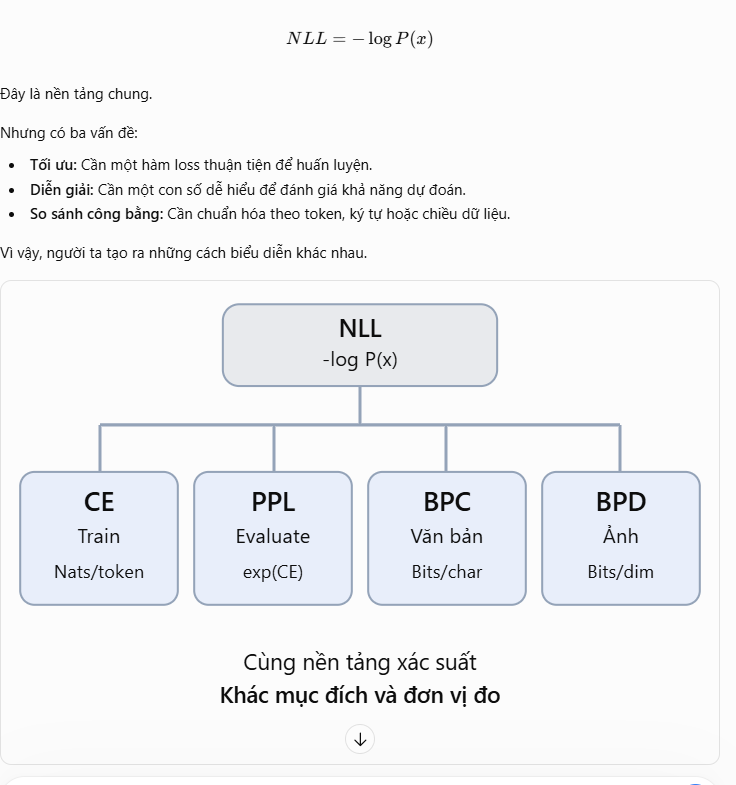

## Exact Evaluation & Functional Correctness

1. Phân biệt hai khái niệm


| Phương pháp            | Bản chất                                                                  | Ví dụ                                |
| --- | --- | --- |
| Exact Evaluation       | Kiểm tra kết quả có khớp chính xác với đáp án hoặc tiêu chí đã định không | So sánh đáp án toán học, JSON, SQL   |
| Functional Correctness | Kiểm tra kết quả có thực hiện đúng chức năng yêu cầu không                | Chạy code, kiểm tra kết quả thực thi |

Bốn nội dung này thuộc nhóm đánh giá chất lượng đầu ra của AI (LLM Evaluation). Khác với Cross Entropy và Perplexity chủ yếu đánh giá xác suất dự đoán token, những phương pháp này tập trung vào câu hỏi:

"Câu trả lời mà AI tạo ra có đúng, có ý nghĩa, có chất lượng và tốt hơn câu trả lời của mô hình khác hay không?"

## 1. Similarity Measurements Against Reference Data

Đo độ tương đồng với dữ liệu tham chiếu

### Bản chất

So sánh câu trả lời AI sinh ra (Prediction) với một đáp án mẫu (Reference / Ground Truth).

Có ba mức độ đánh giá:

| Phương pháp         | Đo cái gì?                   | Ví dụ                                               |
| ------------------- | ---------------------------- | --------------------------------------------------- |
| Exact Match         | Trùng khớp chính xác         | `"Hà Nội"` và `"Hà Nội"`                            |
| Lexical Similarity  | Giống nhau về từ hoặc cụm từ | `"Con mèo đang ngủ"` và `"Mèo đang ngủ"`            |
| Semantic Similarity | Giống nhau về ý nghĩa        | `"Anh ấy rất vui"` và `"Anh ấy cảm thấy hạnh phúc"` |

### A. Exact Match

Kiểm tra hai kết quả có trùng nhau hay không.

\\[ EM(y,\hat y)= \begin{cases} 1 & \text{nếu }y=\hat y\\\ 0 & \text{nếu }y\ne\hat y \end{cases} \\]

Ví dụ:

- Reference: `"Hà Nội"`
- Prediction A: `"Hà Nội"` → 1
- Prediction B: `"Thủ đô Hà Nội"` → 0

Dù B đúng về ý nghĩa, Exact Match vẫn đánh giá sai nếu so khớp chuỗi tuyệt đối.

Khi dùng: Câu trả lời ngắn, nhãn phân loại, đáp án có định dạng cố định.

Không nên dùng: Viết truyện, tóm tắt, diễn đạt lại văn bản vì một ý có thể có nhiều cách viết đúng.

### B. Lexical Similarity

Đánh giá sự giống nhau về từ ngữ, không nhất thiết phải trùng hoàn toàn.

Hai kỹ thuật chính:

Edit Distance (Levenshtein Distance)

Đếm số thao tác thêm, xóa hoặc thay thế ký tự để biến chuỗi A thành B.

Ví dụ:

```
cat → cut
```

Chỉ cần thay `a` thành `u`, nên Edit Distance = 1.

Edit Distance càng nhỏ thì hai chuỗi càng giống nhau về mặt ký tự.

N-gram Overlap

So sánh các cụm gồm `n` token liên tiếp.

Ví dụ:

```
Reference: Con mèo đang ngủ
Prediction: Con mèo đang chơi
```

Với bigram (n = 2):

- Reference: `Con mèo`, `mèo đang`, `đang ngủ`
- Prediction: `Con mèo`, `mèo đang`, `đang chơi`

Hai câu trùng 2 trong 3 bigram.

Các metric phổ biến:

- BLEU: Thường dùng cho Machine Translation, tập trung vào độ chính xác của n-gram được sinh ra, kèm phạt độ dài.
- ROUGE: Thường dùng cho Text Summarization, đo mức độ bao phủ nội dung tham chiếu qua n-gram hoặc chuỗi con chung.

Khi dùng: Dịch máy, tóm tắt văn bản và các bài toán có đáp án tham chiếu.

Hạn chế: Hai câu khác từ nhưng cùng nghĩa có thể bị chấm thấp.

### C. Semantic Similarity

Đo sự tương đồng về ý nghĩa thay vì chỉ so sánh từ ngữ.

Ví dụ:

> A: "Cậu bé rất vui khi nhận được món quà."

> B: "Đứa trẻ cảm thấy hạnh phúc lúc được tặng quà."

Hai câu khác nhau về từ vựng nhưng có ý nghĩa gần giống nhau.

Có thể dùng mô hình Embedding để chuyển hai câu thành vector rồi tính Cosine Similarity.

Khi dùng: Semantic Search, đánh giá paraphrase, phát hiện văn bản trùng ý, đánh giá câu trả lời có nhiều cách diễn đạt.

Hạn chế: Câu có embedding giống nhau chưa chắc đúng về mặt sự thật. Chẳng hạn, hai câu chỉ khác từ "có" và "không" đôi khi vẫn có độ tương đồng cao.

## 2. Introduction to Embedding

Biểu diễn văn bản thành vector số

### Bản chất

Máy tính không trực tiếp hiểu ý nghĩa của câu chữ. Embedding Model học cách biểu diễn từ, câu hoặc tài liệu thành các vector số.

Ví dụ minh họa:

```
"Con mèo đang ngủ"
       ↓
Embedding Model
       ↓
[0.21, 0.85, -0.32, 0.14, ...]
```

Mỗi số là một thành phần của vector. Các chiều này thường là đặc trưng tiềm ẩn do mô hình học được, không nhất thiết tương ứng với một khái niệm dễ đặt tên.

### Cosine Similarity

Dùng để đo độ tương đồng về hướng giữa hai vector:

\\[ \boxed{\operatorname{sim}(A,B)= \frac{A\cdot B}{\\|A\\|\\|B\\|}} \\]

- Gần 1: Hai vector cùng hướng.
- Gần 0: Hai vector gần vuông góc.
- Gần -1: Hai vector ngược hướng.

Tuy nhiên, độ tương đồng ngữ nghĩa thực tế phụ thuộc vào mô hình embedding và dữ liệu huấn luyện.

Minh họa không gian Embedding 2D

Hình minh họa khái niệm, không phải tọa độ từ mô hình embedding thực tế.

### Embedding dùng để làm gì?

| Ứng dụng            | Cách sử dụng                                       |
| ------------------- | -------------------------------------------------- |
| Semantic Search     | Tìm văn bản có ý nghĩa gần với câu truy vấn        |
| RAG                 | Truy xuất tài liệu liên quan trước khi LLM trả lời |
| Clustering          | Gom các văn bản có nội dung tương tự               |
| Duplicate Detection | Phát hiện câu hỏi hoặc tài liệu gần trùng nhau     |
| Anomaly Detection   | Tìm văn bản khác biệt với những nhóm thông thường  |
| Semantic Evaluation | So sánh ý nghĩa của Prediction và Reference        |

Khi nào không nên chỉ dùng Embedding?

Khi yêu cầu chính xác tuyệt đối như kiểm tra số tiền, ngày tháng, phủ định, công thức hoặc kết quả tính toán. Hai câu gần nhau về ngữ nghĩa vẫn có thể chứa thông tin trái ngược.

## 3. AI as a Judge (LLM-as-a-Judge)

Dùng AI làm giám khảo để đánh giá câu trả lời của AI khác

### Bản chất

Thay vì chỉ dùng công thức để so sánh hai chuỗi, ta sử dụng một LLM làm giám khảo.

LLM giám khảo nhận:

- Câu hỏi hoặc yêu cầu ban đầu.
- Câu trả lời do mô hình tạo ra.
- Bộ tiêu chí đánh giá (Rubric).
- Có thể có thêm đáp án tham chiếu hoặc tài liệu xác thực.

Sau đó, LLM đánh giá chất lượng câu trả lời theo các tiêu chí được chỉ định.

Input + AI Response + Rubric

Câu hỏi, câu trả lời, tiêu chí chấm

LLM Judge

Đánh giá theo rubric

Score

8/10

Reason

Giải thích

Feedback

Gợi ý cải thiện

### Hai cách chấm điểm phổ biến

A. Pointwise Evaluation — Chấm điểm độc lập

Giám khảo cho điểm một câu trả lời theo thang điểm, ví dụ 1–10.

Ví dụ với bài toán sinh truyện thiếu nhi:

| Tiêu chí       | Điểm  |
| -------------- | ----- |
| Đúng ý tưởng   | 9/10  |
| Mạch lạc       | 8/10  |
| Sáng tạo       | 7/10  |
| Phù hợp trẻ em | 10/10 |

Có thể tổng hợp thành điểm chung bằng trung bình hoặc trung bình có trọng số.

B. Pairwise Evaluation — So sánh hai câu trả lời

Giám khảo được cung cấp hai câu trả lời A và B cho cùng một yêu cầu.

Nhiệm vụ là xác định:

- A tốt hơn B.
- B tốt hơn A.
- Hai câu tương đương hoặc hòa.

### Tại sao phải dùng AI làm giám khảo?

Vì nhiều bài toán không thể đánh giá chỉ bằng Exact Match hoặc BLEU/ROUGE.

Ví dụ yêu cầu:

> Viết truyện thiếu nhi về một chú thỏ nhút nhát học cách dũng cảm.

Hai truyện có thể không trùng bất kỳ câu chữ nào, nhưng cả hai đều đúng chủ đề và có giá trị giáo dục.

Exact Match không phù hợp, còn LLM Judge có thể đánh giá các tiêu chí như tính mạch lạc, mức độ sáng tạo và bài học.

### Hạn chế của AI as a Judge

| Bias                  | Bản chất                                                    | Ví dụ                                                                |
| --------------------- | ----------------------------------------------------------- | -------------------------------------------------------------------- |
| Verbosity Bias        | Thiên vị câu trả lời dài                                    | Truyện 1.000 từ được đánh giá cao hơn truyện 300 từ dù không hay hơn |
| Position Bias         | Thiên vị vị trí A hoặc B                                    | Thường chọn A dù đảo vị trí hai câu trả lời                          |
| Self-enhancement Bias | Có thể ưu tiên đầu ra của cùng mô hình hoặc cùng họ mô hình | GPT chấm câu trả lời GPT cao hơn đối thủ trong một số điều kiện      |

Ngoài ra, LLM Judge cũng có thể đánh giá sai sự thật, thiếu nhất quán hoặc không tuân thủ rubric.

### Cách giảm bias

- Thiết kế rubric rõ ràng.
- Ẩn tên mô hình tạo câu trả lời.
- Đảo vị trí A/B khi so sánh.
- Chấm lặp lại và kiểm tra tính nhất quán.
- Đối chiếu một phần kết quả với đánh giá của con người.
- Sử dụng kiểm tra khách quan cho các tiêu chí có thể xác minh.

### Khi nào dùng và không nên dùng?

Nên dùng: Đánh giá truyện, hội thoại, tóm tắt, giải thích và các câu trả lời mở.

Không nên chỉ dùng: Đánh giá kết quả toán học, tính đúng đắn của code hoặc các dữ kiện cần chính xác tuyệt đối khi đã có công cụ xác minh đáng tin cậy.

## 4. Ranking Models with Comparative Evaluation

Xếp hạng nhiều mô hình dựa trên các cuộc so sánh

### Bản chất

Thay vì hỏi:

> Model A được bao nhiêu điểm?

Ta hỏi:

> Với cùng một câu hỏi, Model A hay Model B trả lời tốt hơn?

Lặp lại quá trình trên nhiều câu hỏi và nhiều cặp mô hình để xây dựng bảng xếp hạng tổng thể.

### Ví dụ

Giả sử có ba mô hình sinh truyện: LSTM, GPT-2 và Transformer.

Kết quả giả định:

| Trận so sánh         | Mô hình thắng |
| -------------------- | ------------- |
| LSTM vs GPT-2        | GPT-2         |
| LSTM vs Transformer  | Transformer   |
| GPT-2 vs Transformer | Transformer   |

Nếu có đủ số lượng đánh giá đáng tin cậy, ta có thể ước lượng thứ hạng các mô hình.

### A. Elo Rating

Elo là hệ thống xếp hạng dựa trên kết quả đối đầu, vốn nổi tiếng trong cờ vua.

Công thức xác suất thắng kỳ vọng của A trước B:

\\[ E_A=\frac{1}{1+10^{(R_B-R_A)/400}} \\]

Cập nhật điểm:

\\[ R'\_A=R_A+K(S_A-E_A) \\]

Trong đó:

- \\(R_A,R_B\\): Điểm Elo hiện tại.
- \\(E_A\\): Điểm kỳ vọng của A.
- \\(S_A\\): Kết quả thực tế (1 thắng, 0.5 hòa, 0 thua).
- \\(K\\): Hệ số điều chỉnh.

Ví dụ A có Elo 1.200, B có Elo 1.400. Nếu A thắng B, điểm A sẽ tăng đáng kể vì kết quả vượt kỳ vọng.

### B. Bradley–Terry Model

Đây là mô hình xác suất dùng để ước lượng độ mạnh tương đối từ kết quả so sánh cặp.

\\[ P(A>B)=\frac{e^{s_A}}{e^{s_A}+e^{s_B}} \\]

Trong đó \\(s_A,s_B\\) là các tham số thể hiện sức mạnh tương đối của mô hình.

Mô hình có tham số cao hơn sẽ có xác suất thắng cao hơn trong so sánh cặp.

Bradley–Terry cơ bản mô hình hóa thắng/thua; để xử lý hòa cần quy ước hoặc phần mở rộng phù hợp.

### Minh họa bảng xếp hạng

Điểm Elo giả định sau nhiều lượt đánh giá

1K1.2K1.3K1.4K1.6KTransformerGPT-2LSTM

Điểm minh họa, không phải kết quả benchmark thực tế.

### Khi nào dùng?

- Khi cần xếp hạng nhiều Language Models.
- Khi xây dựng benchmark so sánh chatbot.
- Khi người đánh giá dễ chọn câu tốt hơn hơn là cho điểm tuyệt đối.
- Khi muốn đánh giá sở thích của người dùng giữa các câu trả lời.

### Hạn chế

- Cần nhiều lượt so sánh để có kết quả ổn định.
- Chi phí tăng khi số lượng mô hình và câu hỏi tăng.
- Giám khảo có thể thiên vị hoặc thiếu nhất quán.
- Kết quả phụ thuộc vào tập câu hỏi, đối tượng đánh giá và phương pháp xếp hạng.
- Không đảm bảo mô hình xếp hạng cao sẽ tốt nhất trong mọi lĩnh vực.

## 5. So sánh cả 4 phương pháp

| Phương pháp             | Đánh giá điều gì?                               | Khi nào dùng?                                         |
| ----------------------- | ----------------------------------------------- | ----------------------------------------------------- |
| Similarity Measurements | Câu trả lời giống đáp án tham chiếu đến mức nào | QA, dịch máy, tóm tắt, paraphrase                     |
| Embedding               | Biểu diễn và so sánh ngữ nghĩa qua vector       | Semantic Search, RAG, clustering, semantic similarity |
| AI as a Judge           | Chất lượng câu trả lời theo tiêu chí            | Truyện, hội thoại, câu trả lời mở                     |
| Comparative Evaluation  | Mô hình nào được đánh giá tốt hơn qua đối đầu   | Benchmark, xếp hạng nhiều LLM                         |

Lưu ý: Embedding là một kỹ thuật biểu diễn dữ liệu, không tự nó là metric. Cosine Similarity hoặc các metric khác mới được áp dụng lên embedding để đánh giá độ tương đồng.

## 6. Tại sao cần cả 4 thay vì chỉ một?

Vì chúng giải quyết các vấn đề khác nhau.

Giả sử bạn đang đánh giá mô hình sinh truyện thiếu nhi từ một ý tưởng.

| Câu hỏi cần trả lời                                       | Phương pháp phù hợp                             |
| --------------------------------------------------------- | ----------------------------------------------- |
| Truyện sinh ra có giống truyện mẫu không?                 | Similarity Measurements                         |
| Truyện có cùng chủ đề, ý nghĩa với ý tưởng đầu vào không? | Embedding Similarity, kết hợp kiểm tra nội dung |
| Truyện có mạch lạc, sáng tạo và phù hợp trẻ em không?     | AI as a Judge + Human Evaluation                |
| Trong 3 mô hình, mô hình nào viết truyện tốt hơn?         | Comparative Evaluation                          |

Đặc biệt, không nên dùng độ tương đồng với truyện mẫu làm thước đo duy nhất cho tính sáng tạo. Một truyện hoàn toàn mới vẫn có thể rất hay và đúng ý tưởng, dù không giống truyện tham chiếu.

## 7. Tổng kết dễ nhớ

- Similarity: So với đáp án mẫu, giống nhau bao nhiêu?
- Embedding: Hai văn bản có gần nhau về mặt ngữ nghĩa không?
- AI Judge: Câu trả lời có tốt theo những tiêu chí cụ thể không?
- Ranking: Giữa nhiều mô hình, mô hình nào thường được đánh giá cao hơn?

Với dự án sinh truyện tiếng Việt, bạn có thể dùng Perplexity để đánh giá khả năng dự đoán token, AI as a Judge để đánh giá chất lượng truyện, và Pairwise Evaluation để so sánh các mô hình. Đây là ba góc nhìn bổ sung cho nhau, thay vì ba cách đo lặp lại cùng một thứ.

Cả 4 phần đều có thể triển khai bằng code Python, không chỉ là lý thuyết. Tuy nhiên, cần phân biệt: Similarity và Embedding thường dùng công thức hoặc mô hình để tính điểm; AI as a Judge dùng LLM để chấm; còn Comparative Evaluation dùng kết quả đối đầu để xếp hạng.

Mình sẽ lấy cùng một bài toán sinh truyện thiếu nhi để minh họa cả 4 phương pháp, giúp bạn thấy khi nào sử dụng từng phương pháp và code thực hiện ra sao.

## Bài toán chung

Input:

> Viết một câu chuyện ngắn về chú thỏ nhút nhát giúp bạn sóc tìm đường về nhà.

Reference:

> Một chú thỏ nhút nhát gặp bạn sóc bị lạc trong rừng. Dù rất sợ bóng tối, thỏ vẫn dũng cảm dẫn sóc về nhà.

Hai mô hình sinh ra:

Model A:

> Chú thỏ thấy sóc bị lạc trong rừng. Dù rất sợ hãi, thỏ vẫn quyết định giúp sóc tìm đường về nhà.

Model B:

> Một chú thỏ sống trong khu rừng xinh đẹp. Mỗi ngày, thỏ thích ăn cà rốt và chơi cùng các bạn.

Ta sẽ đánh giá hai mô hình bằng 4 phương pháp.

## 1. Similarity Measurements — So sánh với đáp án mẫu

Dùng khi: Bạn có câu trả lời chuẩn (reference) và muốn đo câu trả lời mô hình giống đáp án chuẩn đến mức nào.

### Code Python

```
# pip install rapidfuzz rouge-score sacrebleu

from rapidfuzz.fuzz import ratio
from rouge_score import rouge_scorer
import sacrebleu

reference = (
    "Một chú thỏ nhút nhát gặp bạn sóc bị lạc trong rừng. "
    "Dù rất sợ bóng tối, thỏ vẫn dũng cảm dẫn sóc về nhà."
)

model_a = (
    "Chú thỏ thấy sóc bị lạc trong rừng. "
    "Dù rất sợ hãi, thỏ vẫn quyết định giúp sóc tìm đường về nhà."
)

model_b = (
    "Một chú thỏ sống trong khu rừng xinh đẹp. "
    "Mỗi ngày, thỏ thích ăn cà rốt và chơi cùng các bạn."
)

# 1. Exact Match
def exact_match(prediction, reference):
    return int(prediction.strip() == reference.strip())

# 2. Fuzzy Matching
def fuzzy_similarity(prediction, reference):
    return ratio(prediction, reference) / 100

# 3. ROUGE-L
scorer = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=False
)

def rouge_l(prediction, reference):
    result = scorer.score(reference, prediction)
    return result["rougeL"].fmeasure

# 4. BLEU
def bleu_score(prediction, reference):
    return sacrebleu.sentence_bleu(
        prediction,
        [reference],
        tokenize="char"
    ).score

for name, prediction in [
    ("Model A", model_a),
    ("Model B", model_b)
]:
    print(f"\n{name}")
    print("Exact Match:", exact_match(prediction, reference))
    print("Fuzzy:", fuzzy_similarity(prediction, reference))
    print("ROUGE-L:", rouge_l(prediction, reference))
    print("BLEU:", bleu_score(prediction, reference))
```

Lưu ý: `rouge_score` mặc định tách từ theo quy tắc thiên về tiếng Anh, nên kết quả ROUGE trên tiếng Việt có dấu có thể không đáng tin cậy. Trong dự án thực tế, nên tách từ tiếng Việt và dùng implementation hỗ trợ tokenizer tùy chỉnh.

### Khi nào chọn metric nào?

| Metric         | Khi nên dùng                                | Khi không nên dùng                   |
| -------------- | ------------------------------------------- | ------------------------------------ |
| Exact Match    | Đáp án có một dạng chính xác                | Truyện, thơ, diễn đạt tự do          |
| Fuzzy Matching | Phát hiện chuỗi gần trùng hoặc lỗi chính tả | Đánh giá ý nghĩa sâu                 |
| BLEU           | Dịch máy, so sánh n-gram với reference      | Đánh giá tính sáng tạo               |
| ROUGE          | Tóm tắt, đo mức độ bao phủ nội dung         | Đánh giá toàn diện chất lượng truyện |

Với bài toán sinh truyện, Model A có nội dung gần reference hơn, nhưng không nên dùng điểm lexical similarity để kết luận truyện A hay hơn B về mọi mặt.

## 2. Embedding — So sánh độ tương đồng ngữ nghĩa

Dùng khi: Hai câu khác từ vựng nhưng bạn muốn biết chúng có cùng ý nghĩa hay không.

Ví dụ:

- "Chú thỏ giúp sóc về nhà."
- "Bạn thỏ hỗ trợ sóc tìm đường trở về."

Hai câu khác nhau về từ nhưng gần giống về ý nghĩa.

### Cài đặt

```
pip install sentence-transformers
```

### Code Python

```
from sentence_transformers import SentenceTransformer
from sentence_transformers import util

model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

reference = (
    "Một chú thỏ nhút nhát gặp bạn sóc bị lạc trong rừng. "
    "Dù rất sợ bóng tối, thỏ vẫn dũng cảm dẫn sóc về nhà."
)

model_a = (
    "Chú thỏ thấy sóc bị lạc trong rừng. "
    "Dù rất sợ hãi, thỏ vẫn quyết định giúp sóc tìm đường về nhà."
)

model_b = (
    "Một chú thỏ sống trong khu rừng xinh đẹp. "
    "Mỗi ngày, thỏ thích ăn cà rốt và chơi cùng các bạn."
)

# Chuyển văn bản thành vector
embeddings = model.encode(
    [reference, model_a, model_b],
    convert_to_tensor=True
)

ref_vector = embeddings[0]
a_vector = embeddings[1]
b_vector = embeddings[2]

# Cosine similarity
score_a = util.cos_sim(
    ref_vector, a_vector
).item()

score_b = util.cos_sim(
    ref_vector, b_vector
).item()

print("Model A:", round(score_a, 4))
print("Model B:", round(score_b, 4))
```

### Bản chất code

Quy trình:

```
Reference ──→ Embedding Model ──→ Vector R
Model A   ──→ Embedding Model ──→ Vector A
Model B   ──→ Embedding Model ──→ Vector B

Cosine(R, A)
Cosine(R, B)
```

Giả sử kết quả:

```
Model A: 0.91
Model B: 0.62
```

Đây là số minh họa, không phải kết quả chạy thực tế.

Model A có ý nghĩa gần reference hơn theo mô hình embedding.

### Khi nào dùng?

- Semantic Search.
- Retrieval-Augmented Generation (RAG).
- Phát hiện văn bản trùng ý.
- So sánh câu trả lời có cách diễn đạt khác nhau.
- Đánh giá mức độ liên quan của truyện với ý tưởng đầu vào.

### Khi nào không nên dùng?

Khi cần kiểm tra độ chính xác tuyệt đối.

Ví dụ:

```
A: Bệnh nhân cần uống 2 viên thuốc.
B: Bệnh nhân cần uống 20 viên thuốc.
```

Hai câu có thể có embedding gần nhau dù thông tin số lượng khác biệt nghiêm trọng.

Vì vậy, Cosine Similarity cao không đồng nghĩa nội dung đúng.

## 3. AI as a Judge — Dùng LLM chấm điểm

Dùng khi: Muốn đánh giá các tiêu chí khó đo bằng công thức như tính sáng tạo, mạch lạc, tính phù hợp với trẻ em.

Ví dụ, yêu cầu AI Judge đánh giá truyện theo 4 tiêu chí:

- Đúng ý tưởng: 0–10.
- Mạch lạc: 0–10.
- Sáng tạo: 0–10.
- Phù hợp trẻ em: 0–10.

### Cài đặt

```
pip install openai
```

### Code Python

Ví dụ dùng API của một LLM làm giám khảo:

```
import os
import json
from openai import OpenAI

client = OpenAI(
    api_key=os.environ["OPENAI_API_KEY"]
)

idea = (
    "Viết truyện thiếu nhi về chú thỏ nhút nhát "
    "giúp bạn sóc tìm đường về nhà."
)

story = (
    "Chú thỏ thấy sóc bị lạc trong rừng. "
    "Dù rất sợ hãi, thỏ vẫn quyết định "
    "giúp sóc tìm đường về nhà."
)

rubric = """
Chấm điểm từ 0 đến 10 cho từng tiêu chí:

1. relevance: Đúng ý tưởng ban đầu.
2. coherence: Câu chuyện mạch lạc.
3. creativity: Có tính sáng tạo.
4. age_appropriateness: Phù hợp trẻ 6-8 tuổi.

Trả về JSON gồm:
relevance, coherence, creativity,
age_appropriateness, reason.
"""

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "Bạn là giám khảo đánh giá "
                "chất lượng truyện thiếu nhi. "
                "Hãy đánh giá theo rubric và "
                "trả về JSON hợp lệ."
            )
        },
        {
            "role": "user",
            "content": f"""
Ý tưởng:
{idea}

Truyện:
{story}

Rubric:
{rubric}
"""
        }
    ],
    response_format={"type": "json_object"},
    temperature=0
)

result = json.loads(
    response.choices[0].message.content
)

print(json.dumps(
    result,
    ensure_ascii=False,
    indent=2
))
```

Ví dụ kết quả giả định:

```
{
  "relevance": 9,
  "coherence": 8,
  "creativity": 6,
  "age_appropriateness": 9,
  "reason": "Truyện đúng chủ đề nhưng còn ngắn."
}
```

Trong thực tế, nên kiểm tra dữ liệu JSON, sử dụng rubric có mô tả rõ từng mức điểm và đánh giá trên nhiều mẫu thay vì một truyện.

### Khi nào dùng?

- Sinh truyện, thơ, nội dung sáng tạo.
- Chatbot hội thoại.
- Đánh giá câu trả lời giải thích.
- Đánh giá chất lượng tóm tắt.
- Kiểm tra câu trả lời có tuân thủ yêu cầu hay không.

### Khi nào không nên dùng?

Khi đã có cách kiểm tra chính xác, rẻ và đáng tin cậy hơn.

Ví dụ:

- Kiểm tra `2 + 3 == 5` → Dùng phép so sánh.
- Kiểm tra code có chạy đúng → Dùng unit test.
- Kiểm tra JSON đúng schema → Dùng JSON Schema validator.

Không cần gọi LLM Judge cho những việc này.

## 4. Comparative Evaluation — So sánh và xếp hạng mô hình

Dùng khi: Bạn có nhiều mô hình và muốn xác định mô hình nào tạo kết quả tốt hơn.

Ví dụ:

- Model A: LSTM.
- Model B: GPT-2.
- Model C: Transformer.

Thay vì chấm từng mô hình độc lập, ta cho các mô hình thi đấu theo cặp.

### Bước 1: So sánh hai câu trả lời

```
import os
import json
from openai import OpenAI

client = OpenAI(
    api_key=os.environ["OPENAI_API_KEY"]
)

def compare_responses(prompt, response_a, response_b):
    evaluation = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[
            {
                "role": "system",
                "content": (
                    "Bạn là giám khảo độc lập. "
                    "So sánh hai câu trả lời dựa trên "
                    "mức độ đúng yêu cầu, mạch lạc "
                    "và chất lượng nội dung. "
                    "Trả về JSON với winner là "
                    "'A', 'B' hoặc 'tie', "
                    "và trường reason."
                )
            },
            {
                "role": "user",
                "content": f"""
Yêu cầu:
{prompt}

Response A:
{response_a}

Response B:
{response_b}
"""
            }
        ],
        response_format={"type": "json_object"},
        temperature=0
    )

    result = json.loads(
        evaluation.choices[0].message.content
    )

    return result


result = compare_responses(
    prompt=(
        "Viết truyện về chú thỏ nhút nhát "
        "giúp sóc tìm đường về nhà."
    ),
    response_a=(
        "Thỏ vượt qua nỗi sợ và giúp sóc về nhà."
    ),
    response_b=(
        "Thỏ sống trong rừng và thích ăn cà rốt."
    )
)

print(result)
```

Ví dụ kết quả:

```
{
  "winner": "A",
  "reason": "Response A đáp ứng đúng yêu cầu hơn."
}
```

### Bước 2: Cập nhật điểm Elo

```
def expected_score(rating_a, rating_b):
    return 1 / (
        1 + 10 ** ((rating_b - rating_a) / 400)
    )


def update_elo(
    rating_a,
    rating_b,
    result,
    k=32
):
    """
    result:
        1.0 = A thắng
        0.5 = hòa
        0.0 = B thắng
    """

    expected_a = expected_score(
        rating_a, rating_b
    )

    expected_b = expected_score(
        rating_b, rating_a
    )

    new_a = rating_a + k * (
        result - expected_a
    )

    new_b = rating_b + k * (
        (1 - result) - expected_b
    )

    return new_a, new_b


# Ban đầu cả hai có 1500 Elo
elo_a = 1500
elo_b = 1500

# Model A thắng
elo_a, elo_b = update_elo(
    elo_a,
    elo_b,
    result=1.0
)

print("Model A:", elo_a)
print("Model B:", elo_b)
```

Kết quả:

```
Model A: 1516.0
Model B: 1484.0
```

### Bước 3: Xếp hạng nhiều mô hình

Ví dụ bảng điểm sau nhiều lần so sánh:

| Model       | Elo  |
| ----------- | ---- |
| Transformer | 1580 |
| GPT-2       | 1520 |
| LSTM        | 1410 |

Các điểm này là minh họa.

Để xếp hạng đáng tin cậy, cần so sánh trên nhiều câu hỏi, đảo vị trí A/B, xử lý trường hợp hòa và kiểm tra độ ổn định của kết quả.

### Khi nào dùng?

- So sánh nhiều mô hình sinh văn bản.
- Benchmark các phiên bản LLM.
- Đánh giá sở thích của người dùng.
- Xây dựng bảng xếp hạng chatbot.

### Khi nào không nên dùng?

- Khi chỉ cần đánh giá một mô hình mà không có đối thủ.
- Khi có metric khách quan đáp ứng đầy đủ mục tiêu.
- Khi dữ liệu đánh giá quá ít để đưa ra thứ hạng đáng tin cậy.

## 5. Tổng kết: Trong code nên chọn cái nào?

| Mục tiêu                         | Phương pháp          | Công cụ Python                     |
| -------------------------------- | -------------------- | ---------------------------------- |
| So sánh kết quả với đáp án chuẩn | Exact Match          | Python `==`                        |
| Kiểm tra chuỗi gần giống nhau    | Fuzzy Matching       | `rapidfuzz`                        |
| Đánh giá dịch máy                | BLEU                 | `sacrebleu`                        |
| Đánh giá tóm tắt                 | ROUGE                | `rouge-score` và tokenizer phù hợp |
| So sánh ý nghĩa hai câu          | Embedding Similarity | `sentence-transformers`            |
| Đánh giá chất lượng truyện       | AI as a Judge        | LLM API                            |
| So sánh hai mô hình              | Pairwise Evaluation  | LLM Judge hoặc Human Judge         |
| Xếp hạng nhiều mô hình           | Elo / Bradley–Terry  | Python, SciPy                      |

### Nếu áp dụng cả 4 cho dự án sinh truyện thiếu nhi

Mình đề xuất quy trình:

Input: Ý tưởng sinh truyện

Model A / Model B / Model C sinh truyện

Similarity

So với reference

Embedding

Độ liên quan ngữ nghĩa

AI Judge

Mạch lạc, sáng tạo

Pairwise

So sánh A với B

Báo cáo đánh giá + Xếp hạng mô hình

Điều quan trọng nhất: Không nhất thiết dùng cả 4 trong mọi dự án. Nếu chỉ có một mô hình sinh truyện, bạn có thể bắt đầu với Embedding Similarity để đo mức độ liên quan đến ý tưởng và AI as a Judge để đánh giá chất lượng truyện. Chỉ cần Comparative Evaluation khi thực sự có nhiều mô hình hoặc nhiều phiên bản cần so sánh.